In [10]:
from pathlib import Path

# Locate the project root
PROJECT_ROOT = Path.cwd().resolve()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

# Define the directory for saving figures
FIGURE_DIR = PROJECT_ROOT / "reports" / "figures"

# Create directory if it doesn't exist
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

print("Figures will be saved to:", FIGURE_DIR)

Figures will be saved to: C:\Users\91882\OneDrive\Desktop\intelligent-credit-risk\reports\figures


In [1]:

from pathlib import Path
import sys
import joblib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.calibration import calibration_curve
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    brier_score_loss,
    log_loss
)

# Allow imports from the project root
PROJECT_ROOT = Path.cwd().resolve()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

sys.path.insert(0, str(PROJECT_ROOT))

from src.feature_engineering import create_features
from src.data_preprocessing import FEATURE_COLUMNS

df = pd.read_csv(
    PROJECT_ROOT / "data/raw/application_train.csv"
)

df = create_features(df)

X = df[FEATURE_COLUMNS]
y = df["TARGET"].astype(int)

print("Data shape:", X.shape)
print("Target rate:", y.mean())


Data shape: (307511, 14)
Target rate: 0.08072881945686496


In [2]:

X_dev, X_test, y_dev, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    stratify=y,
    random_state=42
)

X_train, X_val, y_train, y_val = train_test_split(
    X_dev,
    y_dev,
    test_size=0.25,
    stratify=y_dev,
    random_state=42
)

print("Training:", len(X_train))
print("Validation:", len(X_val))
print("Testing:", len(X_test))


Training: 184506
Validation: 61502
Testing: 61503


In [3]:

models = {
    "Logistic Regression": joblib.load(
        PROJECT_ROOT / "models/logistic_baseline.joblib"
    ),
    "XGBoost": joblib.load(
        PROJECT_ROOT / "models/xgboost.joblib"
    ),
    "LightGBM": joblib.load(
        PROJECT_ROOT / "models/lightgbm.joblib"
    )
}

predictions = {}

for name, model in models.items():
    probabilities = model.predict_proba(X_val)[:, 1]
    predictions[name] = probabilities

    print(f"{name}: {len(probabilities)} predictions")


Logistic Regression: 61502 predictions
XGBoost: 61502 predictions
LightGBM: 61502 predictions


In [4]:

def plot_calibration(y_true, probabilities, model_name):
    actual, predicted = calibration_curve(
        y_true,
        probabilities,
        n_bins=10,
        strategy="quantile"
    )

    fig, ax = plt.subplots(figsize=(7, 5))

    ax.plot(
        [0, 1], [0, 1],
        linestyle="--",
        label="Perfect calibration"
    )

    ax.plot(
        predicted,
        actual,
        marker="o",
        label=model_name
    )

    ax.set_xlabel("Mean predicted probability")
    ax.set_ylabel("Observed positive rate")
    ax.set_title(f"Calibration Curve — {model_name}")
    ax.legend()
    ax.grid(alpha=0.3)

    return fig, ax


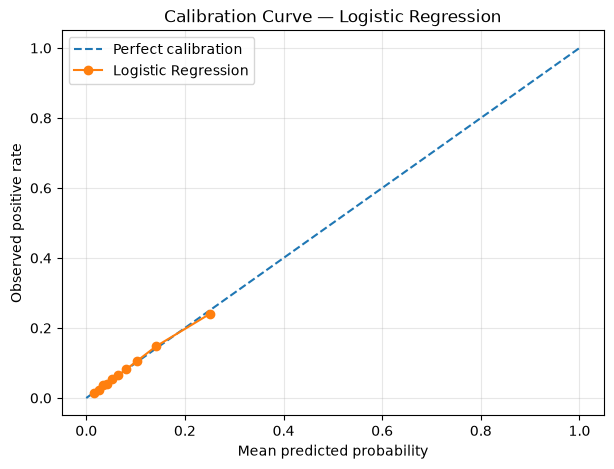

In [5]:

fig, ax = plot_calibration(
    y_val,
    predictions["Logistic Regression"],
    "Logistic Regression"
)

plt.show()


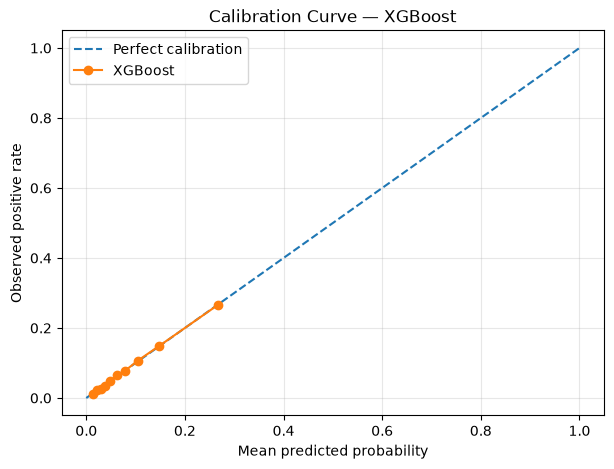

In [ ]:
fig, ax = plot_calibration(
    y_val,
    predictions["XGBoost"],
    "XGBoost"
)



plt.show()

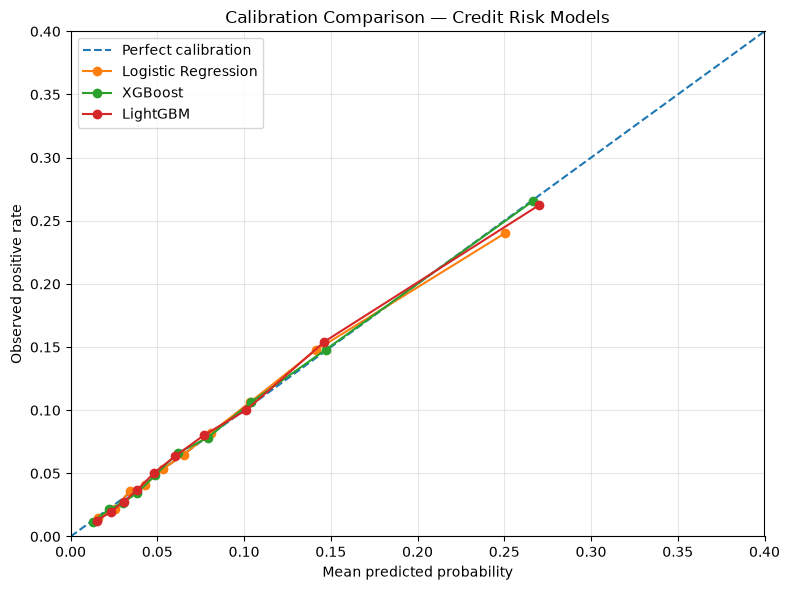

In [7]:

fig, ax = plt.subplots(figsize=(8, 6))

ax.plot(
    [0, 1],
    [0, 1],
    "--",
    label="Perfect calibration"
)

for name, probabilities in predictions.items():

    observed, predicted = calibration_curve(
        y_val,
        probabilities,
        n_bins=10,
        strategy="quantile"
    )

    ax.plot(
        predicted,
        observed,
        marker="o",
        label=name
    )

ax.set_xlabel("Mean predicted probability")
ax.set_ylabel("Observed positive rate")
ax.set_title("Calibration Comparison — Credit Risk Models")
ax.legend()
ax.grid(alpha=0.3)

# The positive class is relatively rare, so this
# view is often more informative than a full 0-1 chart.
ax.set_xlim(0, 0.4)
ax.set_ylim(0, 0.4)

plt.tight_layout()
plt.show()


In [8]:

results = []

for name, probabilities in predictions.items():
    results.append({
        "Model": name,
        "ROC-AUC": roc_auc_score(
            y_val, probabilities
        ),
        "Average Precision": average_precision_score(
            y_val, probabilities
        ),
        "Brier Score": brier_score_loss(
            y_val, probabilities
        ),
        "Log Loss": log_loss(
            y_val, probabilities
        )
    })

comparison = pd.DataFrame(results)

display(comparison.sort_values("ROC-AUC", ascending=False))


,Model,ROC-AUC,Average Precision,Brier Score,Log Loss
1,XGBoost,0.754972,0.234398,0.068191,0.247374
2,LightGBM,0.753455,0.233042,0.068260,0.247822
0,Logistic Regression,0.732716,0.205447,0.069554,0.253632


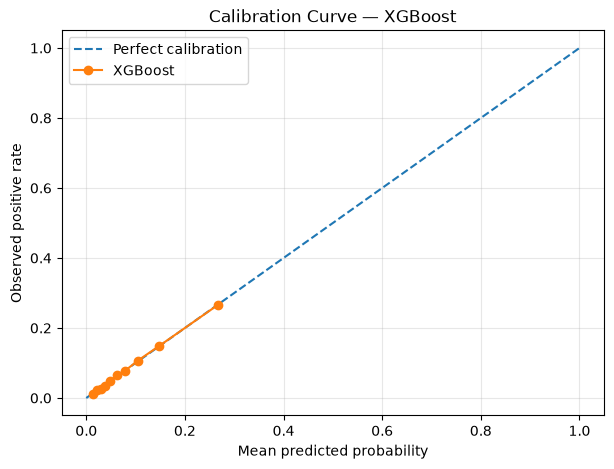

In [11]:
fig, ax = plot_calibration(
    y_val,
    predictions["XGBoost"],
    "XGBoost"
)

fig.savefig(
    FIGURE_DIR / "xgboost_calibration.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()